# Truncated Linear Models for Functional Data (Hall & Hooker 2016)

Suppose we have simulated data where the response $Y_i \in \mathbb{R}$ depends only on the curve $X_i \in L^2(I)$ over a window $[u, v] \in I$:

$$Y_i = \int_u^v X_i(t) \, dt + \varepsilon_i, \qquad \varepsilon_i \sim N(0, \sigma^2),$$

so the true coefficient function is $\beta(t) = \mathbb{1}_{[u, v]}(t)$. This notebook generates data using the `HH_dgp` module.

For this notebook, we let $I=[0, 1]$, along with $u=0.8$ and $v=1.0$ to define the informative region.

We start by importing the necessary packages and generating our data

In [4]:
import numpy as np
from fts_research.core.quadrature import trunc_int
from fts_research.truncFLR import HH_dgp
import matplotlib.pyplot as plt

u, v = 0.8, 1.0
data = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=123)
grid, X, Y = data["grid"], data["X"], data["Y"]
np.shape(X)

(200, 301)

We then plot 20 i.i.d. curves generated by the process, and display the region $$t \in [u, v]$$

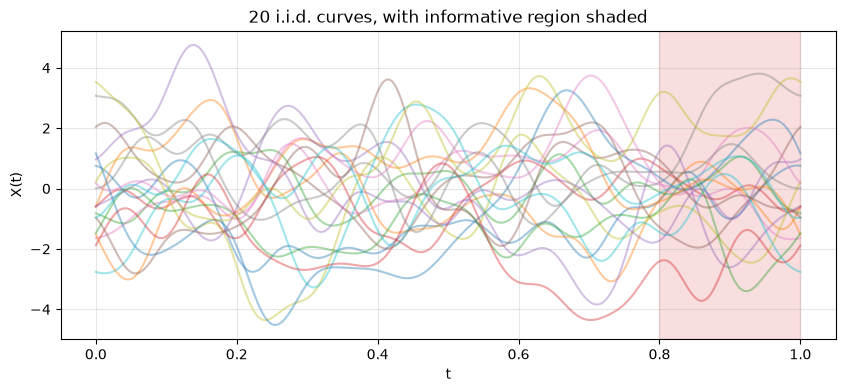

In [2]:
plt.figure(figsize=(10, 4))
plt.plot(grid, X[:20].T, alpha=0.4)
plt.grid(True, alpha=0.3)
plt.axvspan(u, v, alpha=0.15, color="C3")
plt.title("20 i.i.d. curves, with informative region shaded")
plt.xlabel("t")
plt.ylabel("X(t)")
plt.show()

We would then like to make sure $Y$ depends *solely* on $[u, v]$, so we compare two signals:

- `sig_in` — the integral over the true window $[u, v]$. This is simply the generated $Y$ before we added noise to it, so in theory (for a large enough sample), it should correlate with $Y$ perfectly, i.e. the slope of the line of best fit of the scatter plot should be $\approx 1$
- `sig_out` —  the integral over the $I \setminus [u, v]$. There should be no relationship between this region and $Y$, so we expect the slope of the line of best fit to be $\approx 0$

We look at the contrast between the two slopes to confirm this result.

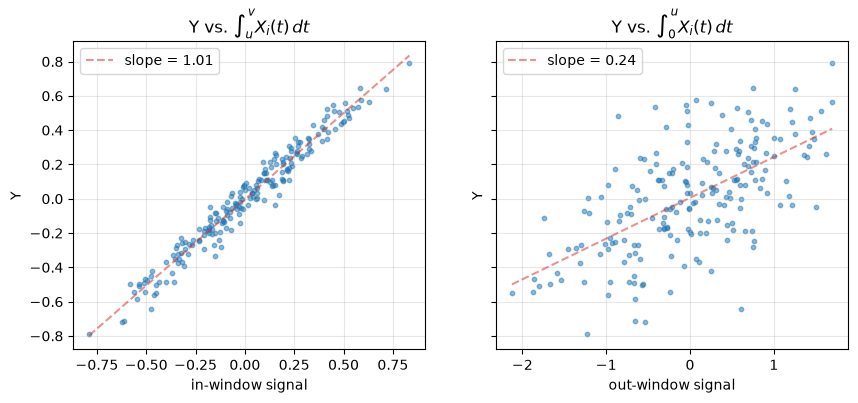

In [3]:
sig_in = trunc_int(X, grid, u, v)
sig_out = trunc_int(X, grid, 0, u)

b_in, a_in = np.polyfit(sig_in, Y, 1)  # Generates the degree 1 polynomial (line) of best fit
b_out, a_out = np.polyfit(sig_out, Y, 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].scatter(sig_in, Y, s=10, alpha=0.5)
xvals_in = np.array([sig_in.min(), sig_in.max()])
ax[0].plot(
    xvals_in, b_in * xvals_in + a_in, ls="--", color="C3", alpha=0.5,
    label=f"slope = {b_in:.2f}"
)
ax[0].grid(True, alpha=0.3)
ax[0].set_xlabel("in-window signal")
ax[0].set_ylabel("Y")
ax[0].set_title(r"Y vs. $\int_u^v X_i(t) \, dt$")
ax[0].legend()

ax[1].scatter(sig_out, Y, s=10, alpha=0.5)
xvals_out = np.array([sig_out.min(), sig_out.max()])
ax[1].plot(
    xvals_out, b_out * xvals_out + a_out, ls="--", color="C3", alpha=0.5,
    label=f"slope = {b_out:.2f}"
)
ax[1].grid(True, alpha=0.3)
ax[1].set_xlabel("out-window signal")
ax[1].set_ylabel("Y")
ax[1].set_title(r"Y vs. $\int_0^u X_i(t) \, dt$")
ax[1].legend()

plt.show()

Clearly, we can see that $Y$ is fully dependent on the informative region we have defined, as expected. However, if we were to discretise this functional model by replacing the integral with a sum over the grid

$$ \int_u^v \beta (t) X_i(t) \, dt \approx \sum^N_{k=1} \beta(t_k) X_i(t_k) \Delta t,$$

where $t_1 = 0$ and $t_N = 1$; and work with the resulting multivariate linear regression model

$$Y_i = \sum^N_{k=1} \beta(t_k) X_i(t_k) \Delta t + \varepsilon_i, \qquad \varepsilon_i \sim N(0, \sigma^2),$$

we can perform OLS on this and find the resulting $\hat{\beta}$.

Given the way we have generated the data and what we have seen up to now, we would guess that the fitted coefficients should concentrate on $[u, v]$ and be around zero elsewhere. The predictors are highly collinear (neighbouring grid points are very close to each other, and each dimension of beta corresponds to a point in time), so $\hat{\beta}$ will be noisy, but the mass should still land in the right place.

We will see that this is not the case, and that when we run unregularised regression, the resulting $\hat{\beta}$ is extremely noisy, and it is impossible to identify the informative region via this method.

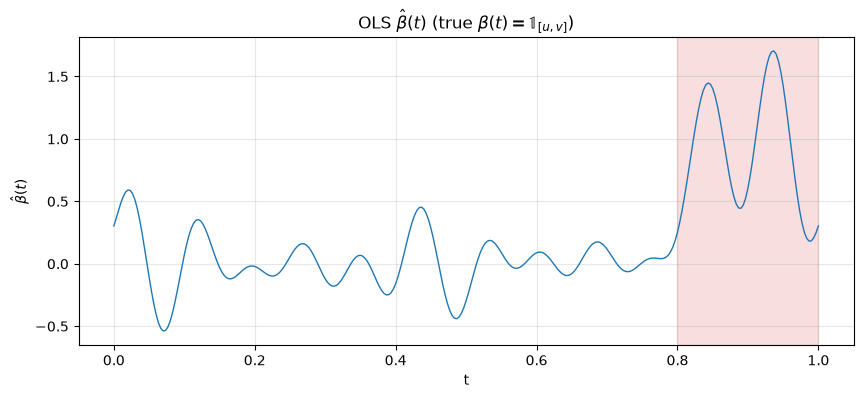

In [4]:
dt = grid[1] - grid[0]

A = X * dt    # Design matrix
A_0 = np.column_stack((np.ones(len(Y)), A))  # Intercept + time point predictors

beta_hat = np.linalg.lstsq(A_0, Y, rcond=None)[0]
beta_hat = beta_hat[1:]

plt.figure(figsize=(10, 4))
plt.plot(grid, beta_hat, lw=1, color="C0")
plt.grid(True, alpha=0.3)
plt.axvspan(u, v, alpha=0.15, color="C3")
plt.title(r"OLS $\hat{\beta}(t)$ (true $\beta(t) = \mathbb{1}_{[u, v]}$)")
plt.xlabel("t")
plt.ylabel(r"$\hat{\beta}(t)$")
plt.show()

We can see that there is no point even comparing the true coefficient function to this estimator. Intuitively, $\hat{\beta}(t)$ being (seemingly) pure noise can be explained by the fact that there is no penalty, hence there is nothing to force it to vanish where it should. We can attempt to amend this using penalisation, as in ridge/lasso regression

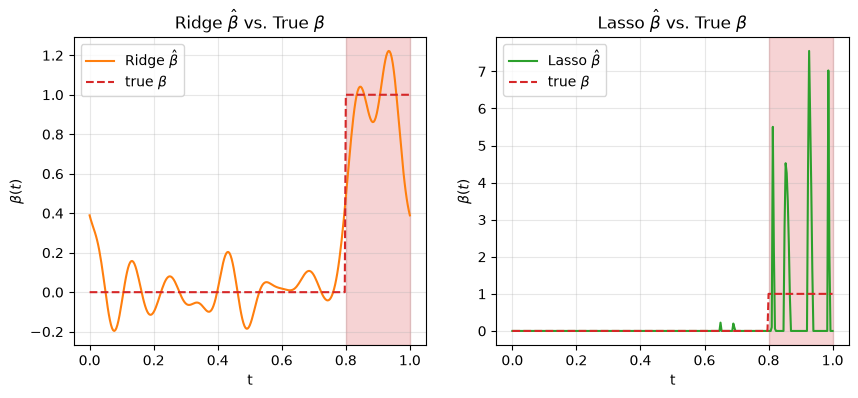

In [5]:
from sklearn.linear_model import RidgeCV, LassoCV

ridge = RidgeCV(alphas=np.logspace(-4, 4, 50)).fit(A, Y)
beta_ridge = ridge.coef_

lasso = LassoCV(alphas=100, cv=5, max_iter=50000, random_state=0).fit(A, Y)
beta_lasso = lasso.coef_

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(grid, beta_ridge, lw=1.5, color="C1", label=r"Ridge $\hat{\beta}$")
ax[0].plot(grid, data["b"], ls="--", color="C3", label=r"true $\beta$")
ax[0].grid(True, alpha=0.3)
ax[0].axvspan(u, v, color="C3", alpha=0.2)
ax[0].set_title(r"Ridge $\hat{\beta}$ vs. True $\beta$")
ax[0].set_xlabel("t")
ax[0].set_ylabel(r"$\beta(t)$")
ax[0].legend()

ax[1].plot(grid, beta_lasso, lw=1.5, color="C2", label=r"Lasso $\hat{\beta}$")
ax[1].plot(grid, data["b"], ls="--", color="C3", label=r"true $\beta$")
ax[1].grid(True, alpha=0.3)
ax[1].axvspan(u, v, color="C3", alpha=0.2)
ax[1].set_title(r"Lasso $\hat{\beta}$ vs. True $\beta$")
ax[1].set_xlabel("t")
ax[1].set_ylabel(r"$\beta(t)$")
ax[1].legend()

plt.show()

These estimators are more accurate than the unregularised one, and we can see that the ridge estimator is scaled well, however it is still fairly noisy outside of the informative region. Lasso does not capture the whole informative region, and the scale of the estimator is inaccurate. Furthermore, neither of these methods actually tell us where the informative region lies.

In the above examples, we discretised the functional representation, and the resulting predictors were highly correlated. Instead of this, we can look at a couple of functional regression methods:

1. FPCA — We represent the curves in a smooth basis (B-spline), keep the $K$ leading FPCs $\{\phi_1(t), \dots, \phi_K(t) \}$, and regress $Y$ on the $K$ scores $\{\psi_1, \dots, \psi_K \}$. Connecting the scores back to the FPCs gives $\hat{\beta}(t) = \sum_k \psi_k \phi_k(t)$

2. FLM w/ smoother — Using the same basis, minimise the squared error plus a curvature penalty $\lambda \int (\beta '')^2 \, dt$.

We import the necessary packages

In [6]:
from skfda import FDataGrid
from skfda.representation.basis import BSplineBasis
from skfda.ml.regression import LinearRegression as MLRLR
from skfda.misc.regularization import L2Regularization
from skfda.misc.operators import LinearDifferentialOperator
from skfda.preprocessing.dim_reduction import FPCA
from sklearn.linear_model import LinearRegression as LMLR

and apply the estimators

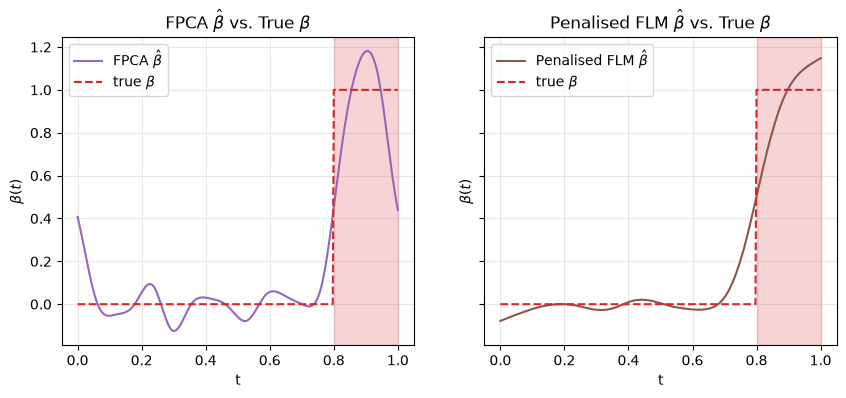

In [7]:
basis = BSplineBasis(n_basis=20, domain_range=(grid[0], grid[-1]))  # B spline of order 4
fd = FDataGrid(X, grid).to_basis(basis)  # Represent discretised functional data as basis

fpca = FPCA(n_components=10)
scores = fpca.fit_transform(fd)  # (n, 10) matrix of each curve's FPC scores
lin = LMLR().fit(scores, Y)  # Regress Y on scores
comps = fpca.components_(grid).squeeze()  # Discretised FPCs on grid
beta_fpca = lin.coef_ @ comps  # Connect scores back to FPCs

reg = L2Regularization(LinearDifferentialOperator(2), regularization_parameter=1e-4)
flm = MLRLR(coef_basis=[basis], regularization=reg).fit(fd, Y)
beta_flm = np.ravel(flm.coef_[0](grid))  # Coefficient function evaluated on grid

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

ax[0].plot(grid, beta_fpca, lw=1.5, color="C4", label=r"FPCA $\hat{\beta}$")
ax[0].plot(grid, data["b"], ls="--", color="C3", label=r"true $\beta$")
ax[0].grid(True, alpha=0.3)
ax[0].axvspan(u, v, color="C3", alpha=0.2)
ax[0].set_title(r"FPCA $\hat{\beta}$ vs. True $\beta$")
ax[0].set_xlabel("t")
ax[0].set_ylabel(r"$\beta(t)$")
ax[0].legend()

ax[1].plot(grid, beta_flm, lw=1.5, color="C5", label=r"Penalised FLM $\hat{\beta}$")
ax[1].plot(grid, data["b"], ls="--", color="C3", label=r"true $\beta$")
ax[1].grid(True, alpha=0.3)
ax[1].axvspan(u, v, color="C3", alpha=0.2)
ax[1].set_title(r"Penalised FLM $\hat{\beta}$ vs. True $\beta$")
ax[1].set_xlabel("t")
ax[1].set_ylabel(r"$\beta(t)$")
ax[1].legend()

plt.show()

We can see that these estimators are both to scale, and the penalised FLM estimator in particular fits extremely well. The curvature penalty means that it is almost flat outside of the informative region, which is exactly what we want. However, the penalty also has the drawback of not allowing the estimator to increase as sharply as it needs to when it reaches the informative region. The FPCA estimator is not bad, and performs similarly to ridge regression, exhibiting a fair amount of noise. Both models still don't allow us to identify the informative region.

We remedy this problem by using the methods from Hall & Hooker [[37]](../docs/references.md#ref-hall-hooker-2016), specifically method B. This method is a two-stage procedure. Stage 1 fits an ordinary FLM without truncation, giving a pilot estimate $(\check{a}, \check{b})$. We use FPCA: represent the curves in a B-spline, keep the $m$ (chosen by BIC) leading FPCs, regress $Y$ on the scores, and map back to a coefficient function on the grid.

In [8]:
from fts_research.truncFLR import HH

In [9]:
a_pilot, b_pilot, fpc = HH.pilot_fpca(X, Y, grid)
print(f"BIC-selected number of FPCs: m = {fpc['m']}")
print(f"pilot intercept a_pilot = {a_pilot:.4f}")

BIC-selected number of FPCs: m = 9
pilot intercept a_pilot = -0.0018


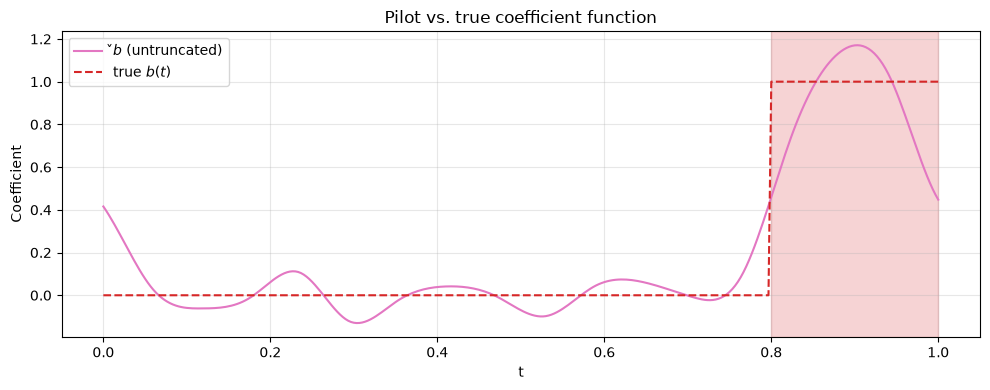

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(grid, b_pilot, color="C6", lw=1.5, label=r"$\check{b}$ (untruncated)")
plt.plot(grid, data["b"], color="C3", lw=1.5, ls="--", label=r"true $b(t)$")
plt.axvspan(u, v, color="C3", alpha=0.2)
plt.grid(True, alpha=0.3)
plt.title("Pilot vs. true coefficient function")
plt.xlabel("t")
plt.ylabel("Coefficient")
plt.legend()
plt.tight_layout()
plt.show()

We can see that the pilot is non-zero even where the true coefficient function is zero. The second stage of the procedure works on recovering the null region and flattening this region of our estimate completely.

Before we can carry out stage 2, we must select the penalty $\lambda$. Standard selection criteria fail in this model, so Hall & Hooker suggest we select $\lambda$ by seeing how well a parametric estimate $\tilde{b}_{simp}$, i.e. a simple curve mimicking the pilot, can be reconstructed after truncation. This scheme builds two error curves as functions of the endpoint:

- $S_Y^B(\theta)$: prediction error (pilot vs. truncated pilot), used to pick the endpoint $\theta_{\lambda}$ for each $\lambda$; \
- $S_b^B(\theta)$: coefficient reconstruction error (parametric vs. truncated pilot), used to score $\lambda$.

The selected $\lambda$ minimises $P_b(\lambda) = \int S_b^B(\theta) N(\theta; \theta_{\lambda}, V(\lambda)) \, d \theta.$

Section 3.2 needs three corrections before it will do this, all of them matters of scale, and `truncFLR_lambdadegen.ipynb` derives and checks them. The variance terms of $S_Y^B$ and $S_b^B$ are per-observation quantities, so they carry a $1/n$ the paper's step 5' omits, and $S_b^B$'s is governed by the full-interval eigenvalues $\tau_j^1$ rather than the truncated $\tau_j^\theta$; equation (3.4) writes the penalty as $n \lambda \theta^2$ where step 6 pairs $S_Y$ with a bare $\lambda$, so step 6's $S_Y$ has to be read as the per-observation error $S_Y/n$; and step 7's integral is taken on a grid fine enough to resolve its density, rather than on the $\theta$ grid. Without them $\hat\lambda$ collapses to the smallest candidate on the grid whatever the data.

In [11]:
lambdas = np.linspace(0.0, 1.0, 250)[1:]

result = HH.fit_mirror(X, Y, grid, lambdas=lambdas)

u_hat = result["u_hat"]
a_hat = result["a_hat"]
b_hat = result["b_hat"]
lam_hat = result["lam_hat"]
diag = result["diag"]

print(f"selected lambda = {lam_hat:.4g}  (grid runs {lambdas[0]:.4g} to {lambdas[-1]:.4g})")
print(f"estimated endpoint u_hat = {u_hat:.4f} (true u = {u})")

selected lambda = 0.07229  (grid runs 0.004016 to 1)
estimated endpoint u_hat = 0.7967 (true u = 0.8)


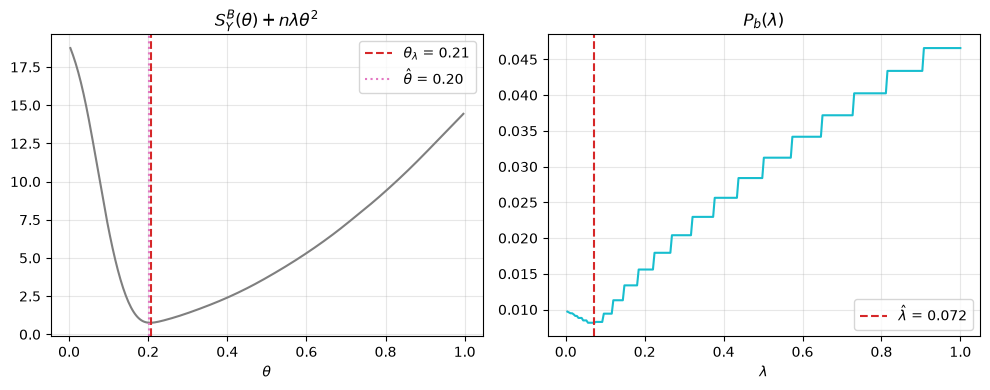

In [12]:
tg = diag["theta_grid"]
S_Y = diag["S_Y"]
S_b = diag["S_b"]
P_b = diag["P_b"]
lams = diag["lambdas"]
theta_hat = result["theta_hat"]

# theta_lam is the argmin of S_Y + n*lam*theta^2 -- the quantity that actually lives on
# this diagnostic plot. theta_hat is the *final* endpoint estimate from the real data (via
# T(theta) in theta_methodB) and is not guaranteed to sit at the minimum of S_Y/S_b.
idx_lam_hat = int(np.nanargmin(P_b))
theta_lam = diag["theta_lams"][idx_lam_hat]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(tg, S_Y + len(Y) * lam_hat * tg ** 2, color="C7", lw=1.5)
ax[0].axvline(theta_lam, color="C3", ls="--", label=fr"$\theta_\lambda$ = {theta_lam:.2f}")
ax[0].axvline(theta_hat, color="C6", ls=":", label=fr"$\hat\theta$ = {theta_hat:.2f}")
ax[0].grid(alpha=0.3)
ax[0].set_title(r"$S_Y^B(\theta) + n\lambda\theta^2$")
ax[0].set_xlabel(r"$\theta$")
ax[0].legend()

ax[1].plot(lams, P_b, color="C9", lw=1.5)
ax[1].axvline(lam_hat, color="C3", ls="--", lw=1.5, label=fr"$\hat\lambda$ = {lam_hat:.3f}")
ax[1].grid(alpha=0.3)
ax[1].set_title(r"$P_b(\lambda)$")
ax[1].set_xlabel(r"$\lambda$")
ax[1].legend()

plt.tight_layout()
plt.show()

Now that we have estimated the endpoint, we can obtain the final coefficient estimate. The paper gives two options: truncate the pilot at $\hat u$ and correct the intercept for the mass removed, or re-run the pilot method on the restricted domain $[\hat u, 1]$. `fit_mirror` takes the second by default (`refit=True`), so $\hat b$ below is a fresh BIC-selected FPCA regression fitted only on the informative window, not a trimmed copy of $\check b$.

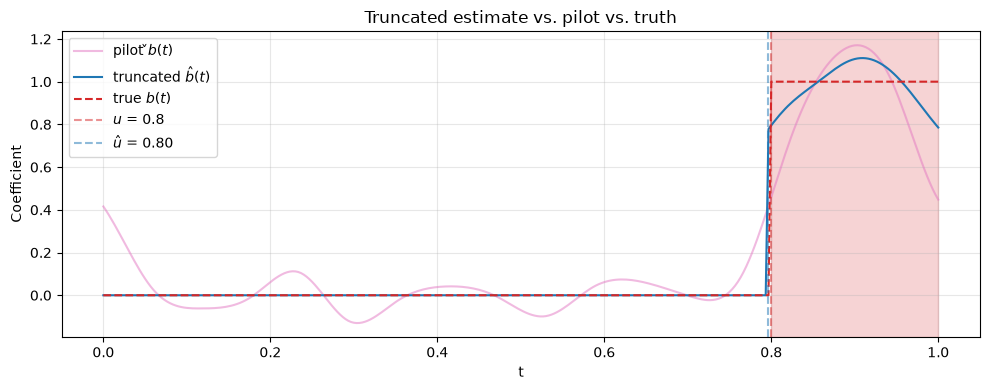

ISE, untruncated pilot  : 0.0211
ISE, truncated estimate : 0.0040


In [13]:
plt.figure(figsize=(10, 4))
plt.plot(grid, b_pilot, color="C6", lw=1.5, alpha=0.5, label=r"pilot $\check{b}(t)$")
plt.plot(grid, b_hat, color="C0", lw=1.5, label=r"truncated $\hat{b}(t)$")
plt.plot(grid, data["b"], color="C3", lw=1.5, ls="--", label=r"true $b(t)$")
plt.axvline(u, color="C3", alpha=0.5, ls="--", label=fr"$u$ = {u}")
plt.axvline(u_hat, color="C0", alpha=0.5, ls="--", label=fr"$\hat u$ = {u_hat:.2f}")
plt.axvspan(u, v, color="C3", alpha=0.2)
plt.grid(alpha=0.3)
plt.title("Truncated estimate vs. pilot vs. truth")
plt.xlabel("t")
plt.ylabel("Coefficient")
plt.legend()
plt.tight_layout()
plt.show()

ise_pilot = np.trapezoid((b_pilot - data["b"]) ** 2, grid)
ise_trunc = np.trapezoid((b_hat - data["b"]) ** 2, grid)
print(f"ISE, untruncated pilot  : {ise_pilot:.4f}")
print(f"ISE, truncated estimate : {ise_trunc:.4f}")

To see the sampling behaviour of $\hat{u}$, we repeat the whole procedure over multiple independent datasets and look at the distribution of the endpoint estimate, as in Hall & Hooker's Figure 1.

In [14]:
# (roughly 2s/replication here) -- this cell takes a few minutes to run.
n_reps = 100
u_hats = np.empty(n_reps)
lam_hats = np.empty(n_reps)
for r in range(n_reps):
    d = HH_dgp.sim_dataset(n=200, u=u, v=v, snr=26.25, rng=r)
    res = HH.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
    u_hats[r] = res["u_hat"]
    lam_hats[r] = res["lam_hat"]

print(f"over {n_reps} replications:")
print(f"mean u_hat = {u_hats.mean():.5f} (true u = {u})")
print(f"sd u_hat = {u_hats.std(ddof=1):.4f}")
print(f"lambda interior to the grid on {(lam_hats > lambdas[0]).sum()}/{n_reps} replications")

over 100 replications:
mean u_hat = 0.79830 (true u = 0.8)
sd u_hat = 0.0102
lambda interior to the grid on 94/100 replications


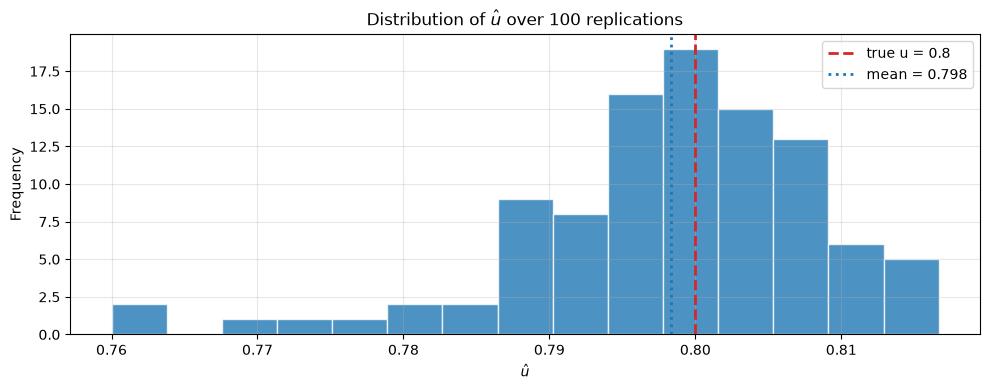

In [15]:
plt.figure(figsize=(10, 4))
plt.hist(u_hats, bins=15, color="C0", alpha=0.8, edgecolor="white")
plt.axvline(u, color="C3", lw=2, ls="--", label=f"true u = {u}")
plt.axvline(u_hats.mean(), lw=2, ls=":", label=f"mean = {u_hats.mean():.3f}")
plt.grid(alpha=0.3)
plt.title(fr"Distribution of $\hat u$ over {n_reps} replications")
plt.xlabel(r"$\hat{u}$")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

We can see that $\hat u$ concentrates just below the true $u$, i.e. method B under-truncates slightly, keeping a little of the null region. That direction is the forgiving one: the estimate is close to zero there anyway, so the cost to $\hat b$ is small, where cutting into the informative region would throw away signal outright.

The model we have looked at so far drops to zero discontinuously. Models 2 and 3 in the paper make $b$ approach zero smoothly at the endpoint, which the paper expects to make truncation more difficult, showing up as a bias towards over-truncation rather than as extra variance. We can generate such a case and measure both the bias and how sharply the criterion picks out the endpoint.

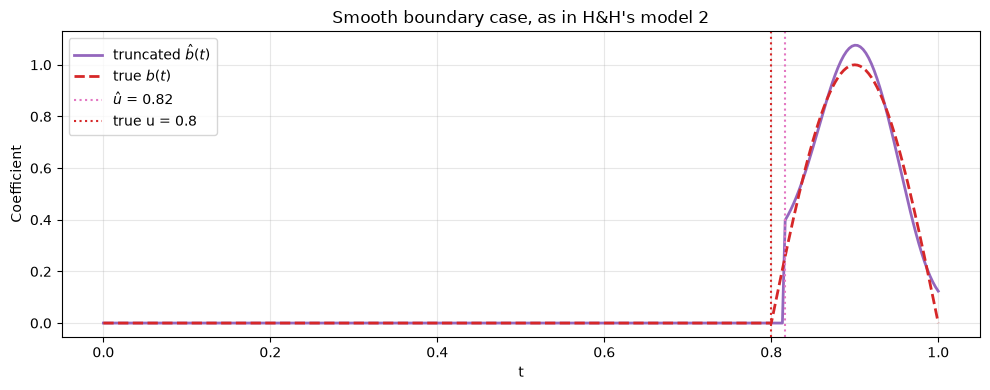

In [16]:
# Half-sine bump on [0.8, 1]
def beta_bump(t, u=u, v=v):
    w = (t >= u) & (t <= v)
    b = np.zeros_like(t)
    b[w] = np.sin(np.pi * (t[w] - u) / (v - u))
    return b


d_bump = HH_dgp.sim_dataset(n=200, u=0.8, v=1.0, snr=26.25, beta_fn=beta_bump, rng=123)
res_bump = HH.fit_mirror(d_bump["X"], d_bump["Y"], d_bump["grid"], lambdas)

plt.figure(figsize=(10, 4))
plt.plot(d_bump["grid"], res_bump["b_hat"], color="C4", lw=2, label=r"truncated $\hat{b}(t)$")
plt.plot(d_bump["grid"], beta_bump(d_bump["grid"]), color="C3", lw=2, ls="--",
         label=r"true $b(t)$")
plt.axvline(res_bump["u_hat"], color="C6", ls=":",
            label=fr"$\hat u$ = {res_bump['u_hat']:.2f}")
plt.axvline(u, color="C3", ls=":", label=f"true u = {u}")
plt.grid(alpha=0.3)
plt.title("Smooth boundary case, as in H&H's model 2")
plt.xlabel("t")
plt.ylabel("Coefficient")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
def profile_width(X, Y, grid, lam, tol=2.0):
    """Width of the set of endpoints fitting essentially as well as the best one.

    Returns the length of the contiguous run of theta around the minimiser on which
    T(theta) <= T_min (1 + tol / n), i.e. within `tol` units of information of the best fit.
    Reported in units of theta, so it is directly comparable with the sampling sd of u_hat,
    and comparable across coefficient functions in a way a raw curvature is not.
    """
    n = len(Y)
    a, b, _ = HH.pilot_fpca(X, Y, grid)
    theta_hat, tg, T = HH.theta_methodB(X, Y, grid, a, b, lam)
    j = int(np.argmin(np.abs(tg - theta_hat)))
    inside = T <= T.min() * (1.0 + tol / n)
    lo = j
    while lo > 0 and inside[lo - 1]:
        lo -= 1
    hi = j
    while hi < len(tg) - 1 and inside[hi + 1]:
        hi += 1
    return tg[hi] - tg[lo]


n_reps_bump = 50
errs = {"indicator": np.empty(n_reps_bump), "half-sine": np.empty(n_reps_bump)}
width = {"indicator": np.empty(n_reps_bump), "half-sine": np.empty(n_reps_bump)}
for r in range(n_reps_bump):
    for name, fn in [("indicator", None), ("half-sine", beta_bump)]:
        d = HH_dgp.sim_dataset(n=200, u=u, v=v, snr=26.25, beta_fn=fn, rng=1000 + r)
        res = HH.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
        errs[name][r] = res["u_hat"] - u
        width[name][r] = profile_width(d["X"][:, ::-1], d["Y"], d["grid"], res["lam_hat"])

print(f"{n_reps_bump} replications per boundary type")
print("bias is reported for theta = 1 - u, the paper's orientation, so a negative bias is")
print("bias towards *more* truncation\n")
print(f"{'boundary':12} {'bias(theta)':>12} {'sd':>8} {'RMSE':>8} {'profile width':>15}")
for name in ("indicator", "half-sine"):
    e = -errs[name]                      # u_hat - u in theta coordinates is -(u_hat - u)
    print(f"{name:12} {e.mean():+12.4f} {e.std(ddof=1):8.4f} "
          f"{np.sqrt((e ** 2).mean()):8.4f} {np.median(width[name]):15.4f}")

50 replications per boundary type
bias is reported for theta = 1 - u, the paper's orientation, so a negative bias is
bias towards *more* truncation

boundary      bias(theta)       sd     RMSE   profile width
indicator         +0.0055   0.0124   0.0135          0.0133
half-sine         -0.0166   0.0082   0.0185          0.0100


The paper's prediction is about where the damage shows up: when $b$ tends to zero smoothly, the
degradation is *"apparent in the observed bias towards more truncation, rather than in the
variance"*. Both halves of that hold here. In $\theta$ coordinates the half-sine carries a bias
of $-0.0166$, i.e. it truncates too much, where the indicator's $+0.0055$ runs the other way;
and the smooth case is the *less* variable of the two, at a sampling standard deviation of
0.0082 against 0.0124. The degradation is entirely in the bias, which is what the paper says to
expect: RMSE 0.0185 against 0.0135.

The profile width says something different, and it is worth keeping the two apart. It is not a
sampling quantity: it is the length of the set of endpoints whose penalised fit is within two
units of information of the best one, on a single dataset, so it measures how sharply that
dataset's criterion picks out its own minimiser rather than how well that minimiser is placed.
At 0.0100 against 0.0133 the smooth boundary is the sharper of the two. The smooth case is
therefore not badly *located* by the criterion; it is well located and systematically displaced.

The reason is that method B's pilot $\check b$ is a smooth FPCA fit, which cannot represent a
discontinuity. The reconstruction error it carries near $t = u$ is worst exactly where $b$
jumps, and that is what flattens the indicator's profile. The smooth target is the one this
machinery is built for, and it pays for the fit with bias instead: a coefficient that dies away
towards the endpoint leaves the scan little to detect there, so it stops short.

For the same problem attacked by re-estimating $(a, b)$ at every candidate endpoint rather
than freezing a pilot, see `truncFLR_methodA.ipynb`.